In [1]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import numpy.random as nr
import jax
import scipy
from gestimators import BF
from IMH2 import IndMH
import matplotlib.pyplot as plt
from gdistribution import gprior, mix_normal
import math

2023-11-30 16:26:49.093711: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [2]:
# def load_data():
#         file = '/home/ranbot/optionpricing/data/ripley.mat'
#         mat = scipy.io.loadmat(file)
#         data = mat['X']
#         inputs = data[:, 0:-1]
#         print(inputs.shape)
#         outputs = data[:, -1]
#         return inputs, outputs

# input, output = load_data()

# n_predata = 50
# def gen_data():
#     X = nr.multivariate_normal(np.zeros(5), np.eye(5), n_predata)
#     y = np.zeros(n_predata)
#     for i in range(n_predata):
#         y[i] = nr.normal(2*X[i,3] + 5*X[i,4], 2.5)
#     #write to file
#     df = pd.DataFrame(X)
#     df['y'] = y
#     df.to_csv('data.csv', index=False)
#     return X, y

# gen_data()

In [3]:
#read from file
def read_data():
    df = pd.read_csv('/home/cliusir/STAT/optionpricing/OPTIONPRICING/gexp/data.csv')
    X = df.values[:, 0:-1]
    y = df.values[:, -1]
    return X, y

input, output = read_data()
input = input[:,3:]
dim = input.shape[1]
N = input.shape[0]
s = 2.5
cov0 = np.linalg.inv(input.T @ input)
print(cov0)
print(dim)
print(N)

[[ 0.01702346 -0.00231604]
 [-0.00231604  0.01804721]]
2
50


In [4]:
def true_mean():
    const = (2*np.pi)**(-N/2)*s**(-N)*np.exp(-0.5*s**(-2)*np.sum(output**2))
    t = np.sum(output[:, np.newaxis]*input, axis=0)
    expcoef = 0.5*s**(-2)*(t.T @ cov0 @ t)
    def integrant(x):
        return const*np.exp(expcoef * x / (x+s**2)) *(1+x/s**2)**(-dim/2) * (1+x)**(-2)
    
    return scipy.integrate.quad(integrant, 0, np.inf)[0]

tm = true_mean()
print(tm)
    

6.749795393026463e-54


10 [0.93292097 0.01482806 0.05225097] [  1.89460473 304.71440759  43.65150364] 0.9999999999999989
20 [0.83451855 0.01285158 0.15262987] [  1.18748495 397.19226233  16.23690508] 1.0000000000000024
30 [0.85287217 0.01162315 0.13550468] [  1.25119435 429.38496063  18.57691587] 0.9999999999999992
40 [0.85397455 0.01144659 0.13457886] [  1.25503061 434.70033739  18.78400225] 0.9999999999999992
50 [0.85405181 0.01143404 0.13451415] [  1.25530101 435.08375396  18.7987546 ] 1.0000000000000002
60 [0.85405725 0.01143316 0.13450959] [  1.25532008 435.11080095  18.79979521] 1.0000000000000027
70 [0.85405764 0.0114331  0.13450926] [  1.25532143 435.11270775  18.79986858] 0.9999999999999982
80 [0.85405767 0.01143309 0.13450924] [  1.25532152 435.11284218  18.79987375] 1.0000000000000022
90 [0.85405767 0.01143309 0.13450924] [  1.25532153 435.11285165  18.79987411] 1.0000000000000004
100 [0.85405767 0.01143309 0.13450924] [  1.25532153 435.11285232  18.79987414] 1.0000000000000016
110 [0.85405767 0.0

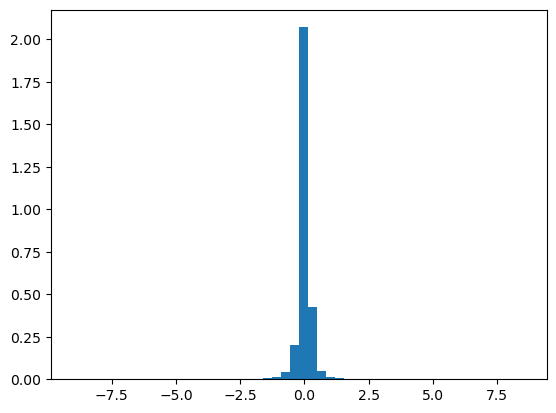

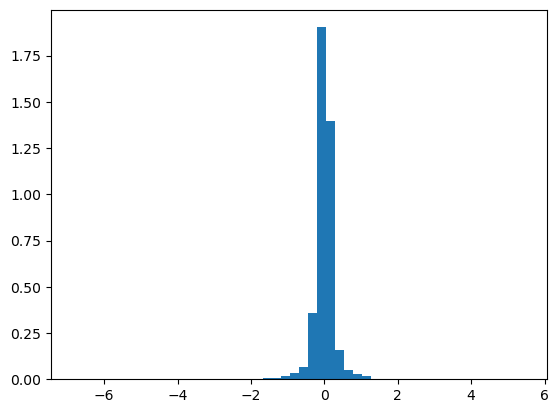

In [5]:
nc = 3
tar = gprior(dim)
tar.set_parameters(cov0)
pro = mix_normal(dim)
a = tar.sampler(10000)

pro.em_algorithm(a,nc,cov0,301)
weights = pro.weights
covs = pro.covs
gs = pro.gs
print(weights, covs, gs)

# covs = np.array([np.cov(a[:,0], a[:,1])])
b = pro.sampler(10000)
plt.hist(a[:,0], bins = 50, density = True)
plt.show()
plt.hist(b[:,0], bins = 50, density = True)
plt.show()

In [6]:
Itrnum = 2100
sample_size = 2000
target = 'gprior'
proposal = 'mix_normal'

MyIM = IndMH(Itrnum, dim, target, proposal)
MyIM.set_distribution_parameters(cov0, nc, weights, covs)
est = BF(sample_size, weights, cov0, gs, input, output)
estcmc = BF(sample_size, weights, cov0, gs, input, output)
tar = gprior(dim)
tar.set_parameters(cov0)

6.544272627017208e-59
6.544272627017208e-59


In [7]:
epoch = 50
cmc_mean = []
imhcv_mean = []
print("start")
for i in range(epoch):
    data = MyIM.IMH()
    est.sample_loader(data[0],data[1],data[2])
    m,v= est.IM()
    imhcv_mean.append(m)
    datacmc = tar.sampler(sample_size)
    estcmc.cmc_loader(datacmc)
    mc,vc = estcmc.CMC()
    # mc,vc = est.IM()
    cmc_mean.append(mc)
    if (i + 1) % 10 == 0:
        print(i + 1, "replications completed ! Acceptance rate:", data[2].mean())

start
10 replications completed ! Acceptance rate: 1.0
20 replications completed ! Acceptance rate: 1.0
30 replications completed ! Acceptance rate: 1.0
40 replications completed ! Acceptance rate: 1.0
50 replications completed ! Acceptance rate: 1.0


In [11]:
var_imhcv = np.array(imhcv_mean).var()
var_cmc = np.array(cmc_mean).var()
print('VAR_IMCV:', var_imhcv)
print('VAR_CMC:',var_cmc)
mean_imhcv = np.array(imhcv_mean).mean()
mean_cmc = np.array(cmc_mean).mean()
error_imhcv = mean_imhcv - tm
error_cmc = mean_cmc - tm
print('True mean:',tm)
print('IMCV:',mean_imhcv,'error:', np.abs(error_imhcv))
print('CMC:',mean_cmc, 'error:',np.abs(error_cmc))

print('VRF:',var_cmc/var_imhcv)

VAR_IMCV: 1.275052701177554e-111
VAR_CMC: 1.0329629744651145e-105
True mean: 6.749795393026463e-54
IMCV: -1.2757085230987495e-56 error: 6.76255247825745e-54
CMC: 5.321211948830332e-54 error: 1.428583444196131e-54
VRF: 810133.5525277806
